In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
import glob
import joblib
import umap
from statistics import mean

sys.path.insert(0, "./cellular_cycle") # add path to the model

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
#DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/dist_runs/')
#SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

/Users/darren/mambaforge/envs/ECM_model/lib/python3.10/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/Users/darren/mambaforge/envs/ECM_model/lib/python3.10/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/Users/darren/mambaforge/envs/ECM_model/lib/python3.10/site-

In [2]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 0.6

In [3]:
# Importing the parameters:
new_param = pd.read_csv(Path('model_data/parameters.csv'))
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Unnamed: 0


In [4]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation

<Axes: xlabel='Time (h)', ylabel='Concentration'>

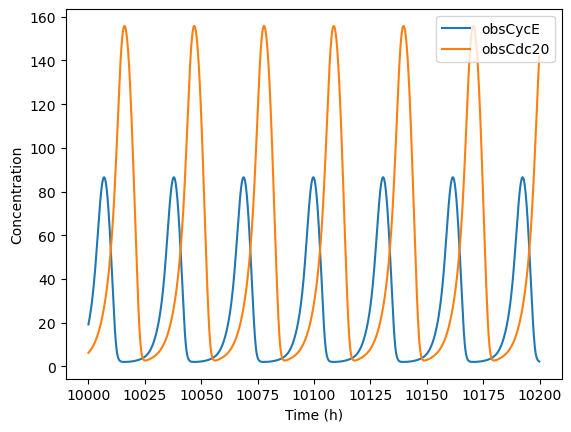

In [5]:
observables=['obsCycE','obsCdc20']; #plot Cyclin E, Cdc20 and Cyclin A

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(100000,102000), legend=True)


In [6]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.6,1,50))
tmp = [1]*50
AKTs.extend(tmp)
ERKs = [1]*100

In [7]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100

In [8]:
model.parameters['FAK'].value = FAKs[24]
model.parameters['AKT'].value = AKTs[24]
model.parameters['ERK'].value = ERKs[24]

In [9]:
simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation
yout = simres.observables;
filename = Path(SAVE_DIR, f'ODE_sim_erl_stiff025_orig.csv')
np.savetxt(filename, yout, delimiter=',')

In [10]:
sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables
filename = Path(SAVE_DIR, f'stoch_sim_erl_stiff025_orig.csv')
np.savetxt(filename, yout, delimiter=',')

In [11]:
model.parameters['FAK'].value = FAKs[74]
model.parameters['AKT'].value = AKTs[74]
model.parameters['ERK'].value = ERKs[74]

In [12]:
simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation
yout = simres.observables;
filename = Path(SAVE_DIR, f'ODE_sim_erl_stiff075_orig.csv')
np.savetxt(filename, yout, delimiter=',')

sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables
filename = Path(SAVE_DIR, f'stoch_erl_stiff075_orig.csv')
np.savetxt(filename, yout, delimiter=',')